# ResNet experts (Pool B)

Trains **one ResNet per expert** (real vs. that expert's fakes), calibrates it, and scores every image the
combiners use with every expert: the ResNet half of the score table. See `resnet/train.py` and `resnet/score.py`.

- **7 experts**, the same as the CLIP pool: ADM, BigGAN, glide, Midjourney, SD (SD 1.4 + 1.5 together), VQDM, wukong (`resnet/experts.py`).
- **Train:** ImageNet-pretrained ResNet, fine-tuned on the expert's own `expert_train` images (random 224 crop + flip).
  `expert_val` picks the best epoch (lowest loss, early stopping) and fits the temperature. No other pool is touched.
- **Score:** every image of `expert_val`, `meta_train`, `meta_val`, `test` (and any pool added later, e.g. a seen-test pool)
  → one raw logit per expert, saved as the feature set `resnet50_experts`. `load_scores()` returns calibrated
  probabilities `sigmoid(logit / T)`.

**Time on an M4 (16 GB), ResNet-50:** ~30 min per expert (≤ 8 epochs of 10k images at ~42 images/s), so ~2.5-3.5 h
for all 7, plus ~1.2 h scoring. `ARCH = "resnet18"` is ~2.5x faster.

**Safe to stop and rerun:** finished experts and scored images are saved and skipped.
Set `LIMIT = 100` first for a test run of the whole notebook (~10 min); it saves to separate folders.

In [4]:
import sys
sys.path.insert(0, "../..")  # repo root, so `common`, `data` and `resnet` are importable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from data import config
from resnet.experts import EXPERTS
from resnet.score import check, load_scores, score
from resnet.train import train_all

ARCH = "resnet50"  # "resnet18" if time is short
LIMIT = None  # e.g. 100 for a test run: 100 images per label and pool, saved separately
EPOCHS = 1 if LIMIT else 8
BATCH_SIZE = 64  # training; lower to 32 if you run out of memory
NUM_WORKERS = 4

print("dataset:", config.dataset_dir(), config.dataset_dir().exists())

dataset: /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c True


## 1 · Train and calibrate the 7 experts

In [5]:
infos = train_all(epochs=EPOCHS, limit=LIMIT, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, arch=ARCH)

[21:47:50] [ADM] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/ADM.pt to retrain)
[21:47:50] [BigGAN] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/BigGAN.pt to retrain)
[21:47:50] [glide] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/glide.pt to retrain)
[21:47:50] [Midjourney] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/Midjourney.pt to retrain)
[21:47:50] [SD] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/SD.pt to retrain)
[21:47:50] [VQDM] already trained, skipping (delete /Users/firasmosbeh/SC4001-Metalearners-Route-or-Pool/input/genimage_d8889a9c/models/resnet50/VQDM.pt to retrain

### Training curves

Validation loss is on each expert's own `expert_val` images. `T` is the calibration temperature:
1 means the expert was already calibrated (or perfectly separated on validation), larger values soften it.

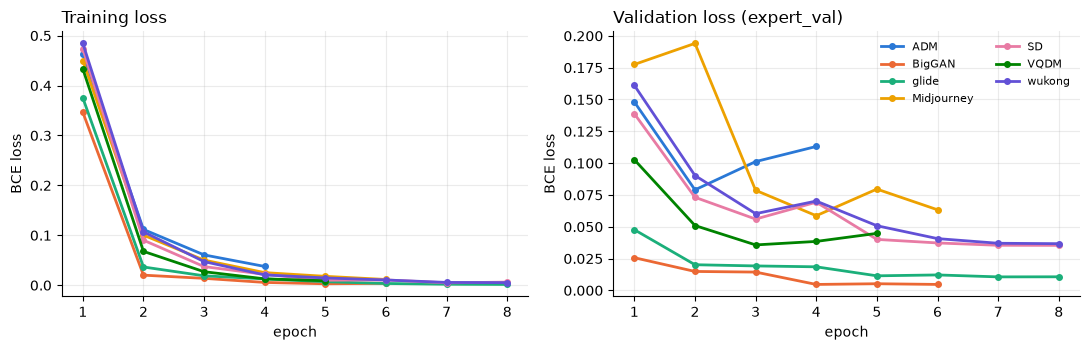

,expert,best epoch,epochs run,val auc,val acc,val loss,calibrated loss,T,minutes
0,ADM,2,4,0.9962,0.9730,0.0790,0.0790,1.0000,19.8833
1,BigGAN,4,6,1.0000,0.9985,0.0047,0.0047,1.0000,25.3500
2,glide,7,8,0.9999,0.9965,0.0106,0.0106,1.0000,35.0500
3,Midjourney,4,6,0.9977,0.9775,0.0587,0.0585,1.0681,29.7167
4,SD,8,8,0.9991,0.9910,0.0354,0.0349,1.1220,45.0000
5,VQDM,3,5,0.9992,0.9870,0.0357,0.0357,1.0000,22.5667
6,wukong,8,8,0.9992,0.9830,0.0367,0.0367,1.0000,40.6667


In [6]:
# Categorical slots in fixed order, one per expert.
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True)
for color, (expert, info) in zip(COLORS, infos.items()):
    history = pd.DataFrame(info["history"])
    axes[0].plot(history.epoch, history.train_loss, color=color, lw=2, marker="o", ms=4, label=expert)
    axes[1].plot(history.epoch, history.val_loss, color=color, lw=2, marker="o", ms=4, label=expert)
for ax, title in zip(axes, ["Training loss", "Validation loss (expert_val)"]):
    ax.set_title(title, loc="left")
    ax.set_xlabel("epoch")
    ax.set_ylabel("BCE loss")
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

pd.DataFrame([{
    "expert": expert, "best epoch": info["best_epoch"], "epochs run": info["epochs_run"],
    "val auc": info["val"]["auc"], "val acc": info["val"]["acc"], "val loss": info["val"]["loss"],
    "calibrated loss": info["val_calibrated_loss"], "T": info["temperature"],
    "minutes": info["train_seconds"] / 60,
} for expert, info in infos.items()]).round(4)

## 2 · Score every image with every expert

In [7]:
score(limit=LIMIT, num_workers=NUM_WORKERS, arch=ARCH)
missing = check(limit=LIMIT, arch=ARCH)

[21:47:51] resnet50_experts: 96000 images in pools ['expert_val', 'meta_train', 'meta_val', 'test'], 96000 done, 0 to do
[21:47:52] resnet50_experts: 96000/96000 images of pools ['expert_val', 'meta_train', 'meta_val', 'test'] have scores, 20 parts
[21:47:52] all good


## 3 · Using the scores in the combiners

Same shape as `data.features.load_features`: `X` has one column per expert in `EXPERTS` order,
`rows` the matching manifest rows. Drop the held-out expert's column per fold.

In [8]:
X, rows = load_scores(pool="meta_train", limit=LIMIT, arch=ARCH)  # calibrated=False for raw logits
print(X.shape, list(EXPERTS))
pd.DataFrame(X, columns=list(EXPERTS)).assign(generator=rows.generator.values, label=rows.label.values).head()

(32000, 7) ['ADM', 'BigGAN', 'glide', 'Midjourney', 'SD', 'VQDM', 'wukong']


,ADM,BigGAN,glide,Midjourney,SD,VQDM,wukong,generator,label
0,0.001412,0.000289,0.000013,0.460271,0.000004,0.000240,0.000097,ADM,0
1,0.004161,0.002924,0.002726,0.020293,0.078601,0.890213,0.007758,ADM,0
2,0.001745,0.000097,0.000039,0.001251,0.000004,0.000048,0.000013,ADM,0
3,0.007359,0.000286,0.000117,0.000636,0.000013,0.001898,0.000094,ADM,0
4,0.000786,0.000129,0.001720,0.012904,0.000067,0.020667,0.000214,ADM,0
